# Repo Health Report: a Managed Agents backend in about 60 lines

**The scenario.** You're adding a **"Repo health"** button to your product. A customer pastes a public GitHub URL, and a few seconds later they get charts showing *when* the project is worked on, *who* works on it, and how activity has changed over time.

Producing that means cloning a repo, running git, installing pandas and matplotlib, and executing code. You'd rather not do that on your web servers, for every customer, with somebody else's repository. So the button's backend hands each request to a **Claude Managed Agent**:

| Concept | In this notebook | Created |
|---|---|---|
| **Environment** | The sandbox template: pandas and matplotlib pre-installed, open network for `git clone` | once |
| **Agent** | Model + "report contract" system prompt + built-in tools | once |
| **Session** | One customer request, in its **own fresh sandbox** | per click |
| **Events** | What streams back while it works | per session |

Watch for three things. First, you write **no agent loop**. Second, **nothing runs on this machine** except printing. Third, the charts come back as **files** from the sandbox.

In [1]:
# %pip install -q anthropic          # ← uncomment on Colab
import json, os, time
from pathlib import Path
from IPython.display import Image, Markdown, display

try:                                   # Colab: add ANTHROPIC_API_KEY under 🔑 Secrets
    from google.colab import userdata
    os.environ.setdefault("ANTHROPIC_API_KEY", userdata.get("ANTHROPIC_API_KEY") or "")
except Exception:
    try:
        from dotenv import load_dotenv; load_dotenv(Path.cwd().parents[1] / ".env")
    except Exception:
        pass

RECORDED = Path("recorded")
REPLAY = os.environ.get("REPLAY") == "1" or not os.environ.get("ANTHROPIC_API_KEY")
print("mode:", "REPLAY (recorded run, no API calls)" if REPLAY else "LIVE")

if not REPLAY:
    from anthropic import Anthropic
    client = Anthropic()
MODEL = "claude-sonnet-5-5"
TAG = {"workshop": "ma201-notebook"}

mode: LIVE


In [2]:
# A tiny event printer, so we can watch the session work.
COLORS = {"sandbox": "\033[34m", "agent": "\033[1m", "status": "\033[2m", "end": "\033[0m"}

def trace(ev, t0):
    t = f"{time.time() - t0:5.1f}s"
    kind = ev["type"]
    if kind == "agent.tool_use":
        cmd = (ev["input"].get("command") or json.dumps(ev["input"]))
        cmd = cmd.splitlines()[0][:90] + (" …" if len(cmd) > 90 or "\n" in cmd else "")
        print(f"{t} {COLORS['sandbox']}sandbox · {ev['name']:<5}{COLORS['end']} {cmd}")
    elif kind == "agent.message":
        text = "".join(b["text"] for b in ev["content"] if b["type"] == "text")
        print(f"{t} {COLORS['agent']}agent{COLORS['end']}  {text}")
    elif kind in ("session.status_running", "session.status_idle"):
        why = ev.get("stop_reason", {}).get("type", "")
        print(f"{t} {COLORS['status']}{kind} {why}{COLORS['end']}")

## 1. The Environment: a template for every sandbox (created once)

This is the "infrastructure" part, and it's a single config object. Each session built from it starts in a **fresh** container with these packages already installed.

In [3]:
def get_or_create_environment():
    for env in client.beta.environments.list():
        if env.name == "repo-health":
            return env.id
    return client.beta.environments.create(
        name="repo-health",
        config={
            "type": "cloud",
            "networking": {"type": "unrestricted"},           # needs to reach GitHub
            "packages": {"type": "packages", "pip": ["pandas", "matplotlib"]},
        },
        metadata=TAG,
    ).id

ENV_ID = "env_recorded" if REPLAY else get_or_create_environment()
ENV_ID

'env_01DC21i6ovcFAqmChe82MymR'

## 2. The Agent: versioned config, not code in your process (created once)

The system prompt is a **contract**: what to produce and where to put it. Files written to `/mnt/session/outputs/` can be downloaded afterwards through the Files API. The built-in toolset gives the agent bash and file tools, and **they run in the sandbox, not here**.

In [4]:
REPORT_CONTRACT = '''You are the backend of a "Repo health" button. Given a public git repository URL:
1. Clone history only: git clone --bare --filter=blob:none <url> /tmp/repo
2. From `git log` build three charts with matplotlib (white background, readable fonts,
   repo name in each title) and save them to /mnt/session/outputs/:
   - heatmap.png: commits by weekday (rows) x hour of day UTC (columns)
   - authors.png: top 10 authors by commit count, horizontal bars
   - activity.png: commits per month across the full history
3. Write /mnt/session/outputs/summary.json with keys: repo, commits, authors,
   first_commit, last_commit, busiest_weekday, bus_factor (fewest authors covering 50%
   of commits), one_line_take.
Be efficient: one script, no exploration. Finish with three short bullets.'''

def get_or_create_agent():
    for a in client.beta.agents.list():
        if a.name == "repo-health":
            return a
    return client.beta.agents.create(
        name="repo-health",
        model=MODEL,
        system=REPORT_CONTRACT,
        tools=[{"type": "agent_toolset_20260401"}],
        metadata=TAG,
    )

if REPLAY:
    AGENT_ID, AGENT_VERSION = "agent_recorded", 1
else:
    agent = get_or_create_agent()
    AGENT_ID, AGENT_VERSION = agent.id, agent.version
print(AGENT_ID, "version", AGENT_VERSION)

agent_01U3SApEvhdcZUEVUB8jvE12 version 1


## 3. A customer clicks the button → a Session

One request becomes one session, with its own sandbox and its own server-side history. The metadata says who the session is for, which is useful for cost attribution and for finding it again later.

We **open the stream before sending** the message so we can't miss early events. Then we just watch.

In [5]:
def run_report(repo_url: str, customer: str) -> str:
    if REPLAY:
        return replay_report(customer)
    session = client.beta.sessions.create(
        agent=AGENT_ID,
        environment_id=ENV_ID,
        title=f"Repo health: {repo_url}",
        metadata={**TAG, "customer": customer, "repo": repo_url},
        budget={"type": "limit", "max_list_cost": {"amount": "50", "currency": "USD"}},
    )
    t0, log = time.time(), []
    with client.beta.sessions.events.stream(session.id) as stream:
        client.beta.sessions.events.send(session.id, events=[
            {"type": "user.message", "content": [{"type": "text", "text": f"Repo: {repo_url}"}]},
        ])
        for event in stream:
            ev = event.model_dump(mode="json")
            log.append(ev)
            trace(ev, t0)
            if event.type == "session.status_terminated" or (
                event.type == "session.status_idle" and event.stop_reason.type != "requires_action"):
                break    # end_turn, budget_reached, refusal, retries_exhausted… all end the turn
    if os.environ.get("RECORD") == "1":
        RECORDED.mkdir(exist_ok=True)
        (RECORDED / f"{customer}_events.jsonl").write_text("\n".join(json.dumps(e) for e in log))
    return session.id

def replay_report(customer: str) -> str:
    log = [json.loads(l) for l in (RECORDED / f"{customer}_events.jsonl").read_text().splitlines()]
    t0 = time.time()
    for ev in log:
        trace(ev, t0)
    return f"sesn_recorded_{customer}"

In [6]:
# Customer A clicks "Repo health" on pallets/markupsafe
SESSION_A = run_report("https://github.com/pallets/markupsafe", customer="acme-corp")

  0.7s session.status_running 


 11.4s sandbox · bash  mkdir -p /mnt/session/outputs && cat > /tmp/health.py <<'EOF' …


 18.2s agent  I cloned `pallets/markupsafe` history-only and saved the three charts and `summary.json` to `/mnt/session/outputs/`. I didn't open the chart images to check them.

- **Summary:** 869 commits from 53 authors, running from 2010-06-22 to 2026-10-03. Friday is the busiest weekday.
- **Bus factor 1:** one author accounts for at least 50% of all commits. The one-line take in `summary.json` says the repo has 25 commits in the year before the latest one.
- **Files:** `heatmap.png`, `authors.png`, `activity.png` and `summary.json`. Authors are counted by name, and the log covers all refs (`git log --all`), not only the default branch.
 18.3s session.status_idle end_turn


## 4. Getting the results: files out of the sandbox

The agent wrote PNGs inside *its* container. The Files API lists every file scoped to that session. Downloading them is the only point where anything touches this machine.

['activity.png', 'authors.png', 'heatmap.png', 'summary.json']


### markupsafe: 869 commits · 53 authors · bus factor **1**
> markupsafe has 869 commits from 53 authors; bus factor 1, 25 commits in the last year before the latest commit.

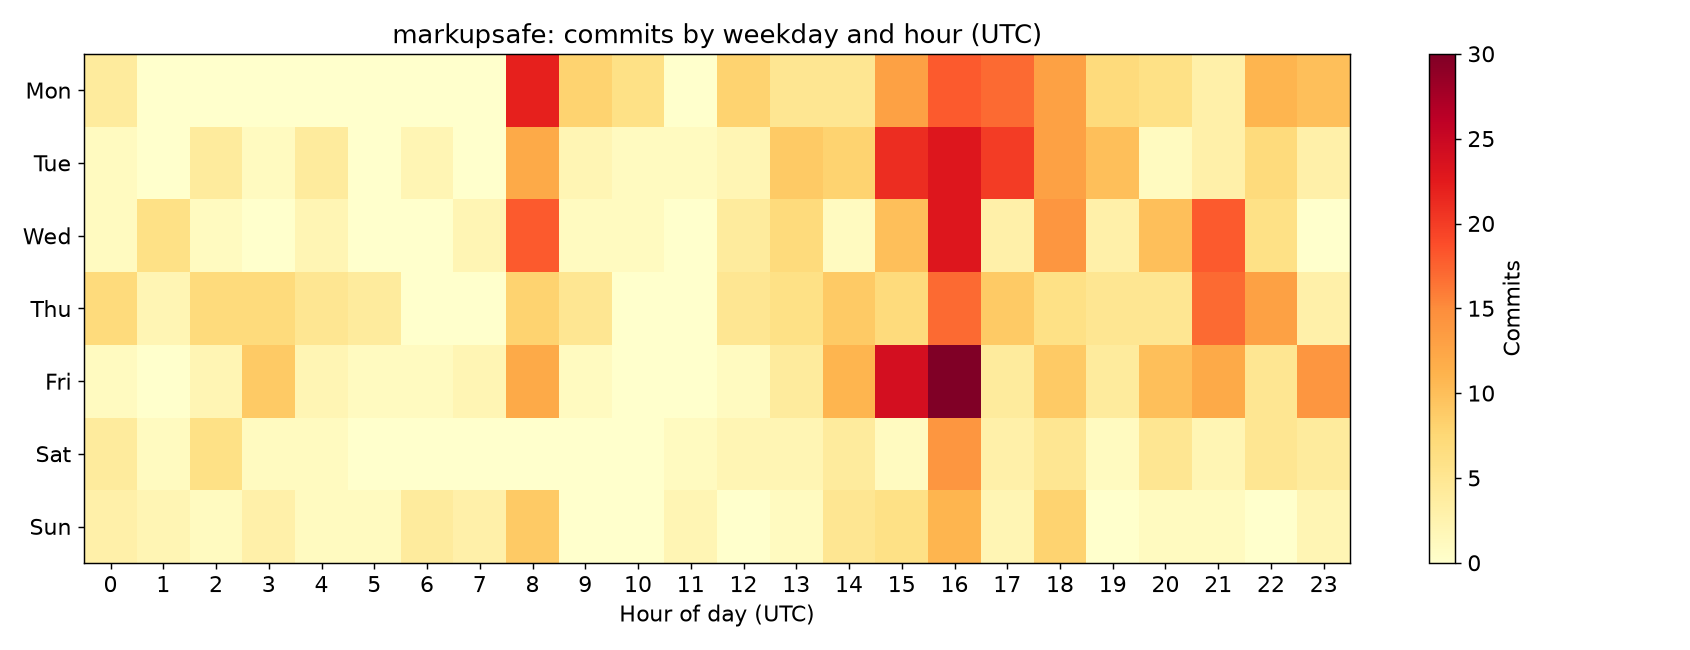

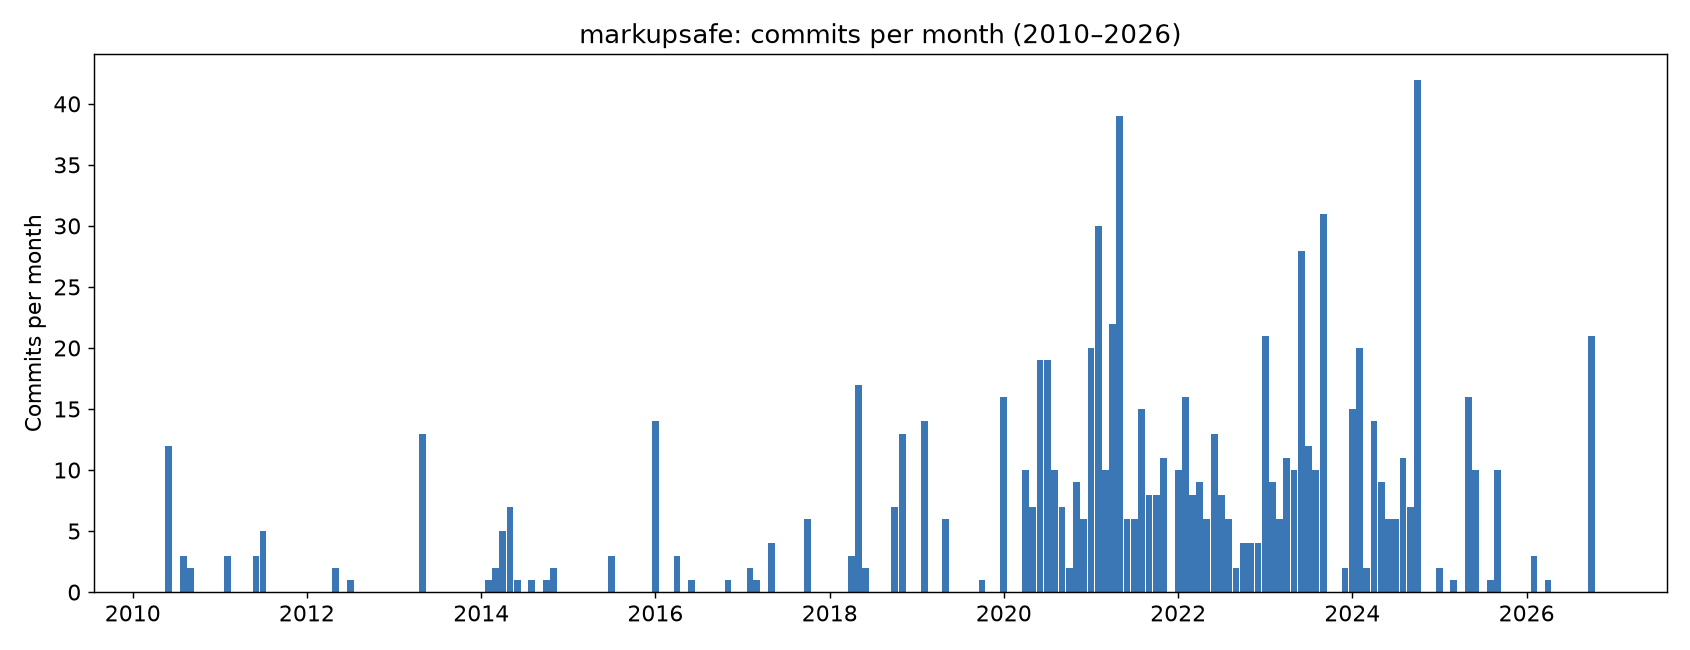

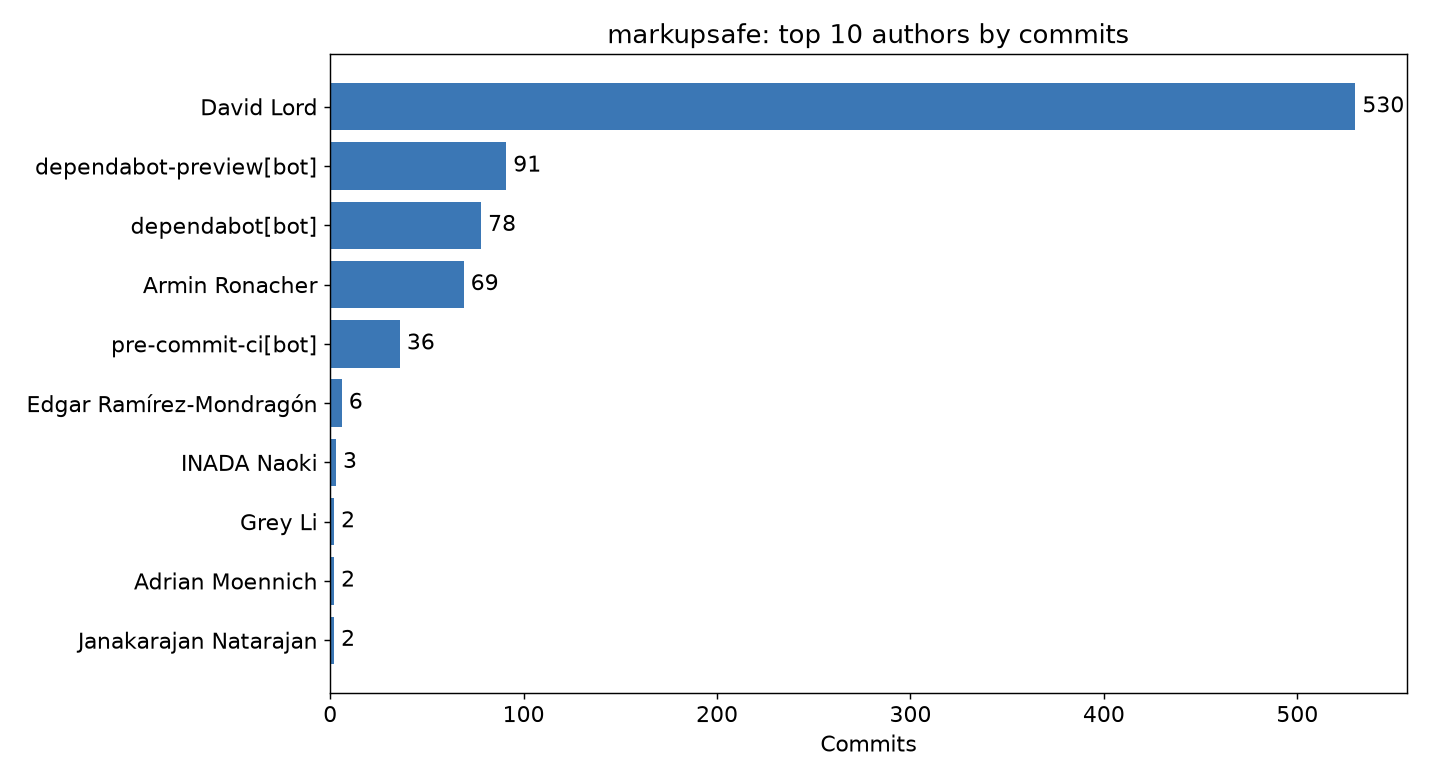

In [7]:
def fetch_outputs(session_id: str, customer: str) -> dict:
    if REPLAY:
        return {p.name.split("_", 1)[1]: p.read_bytes() for p in RECORDED.glob(f"{customer}_*") if p.suffix in (".png", ".json")}
    for _ in range(5):                       # outputs can land a few seconds after idle
        files = client.beta.files.list(scope_id=session_id, betas=["managed-agents-2026-04-01"]).data
        if len(files) >= 4:
            break
        time.sleep(2)
    out = {f.filename: client.files.download(f.id).read() for f in files}
    if os.environ.get("RECORD") == "1":
        for name, data in out.items():
            (RECORDED / f"{customer}_{Path(name).name}").write_bytes(data)
    return out

def show_report(outputs: dict):
    s = json.loads(outputs["summary.json"])
    display(Markdown(f"### {s['repo']}: {s['commits']} commits · {s['authors']} authors · "
                     f"bus factor **{s['bus_factor']}**\n> {s['one_line_take']}"))
    for name in ("heatmap.png", "activity.png", "authors.png"):
        if name in outputs:
            display(Image(outputs[name], width=760))

outputs_a = fetch_outputs(SESSION_A, "acme-corp")
print(sorted(outputs_a))
show_report(outputs_a)

## 5. Meanwhile, another customer…

While we watched Acme's report, a second customer, Globex, ran one on `simonw/sqlite-utils`. That ran **in a separate session and a separate sandbox**, from the **same agent and environment IDs**. Nothing was shared between the two runs except the definition. We recorded it earlier, so here are its results:

### https://github.com/simonw/sqlite-utils: 1500 commits · 55 authors · bus factor **1**
> Simon Willison wrote 91% of 1500 commits (bus factor 1); a long-lived, still-active single-maintainer project.

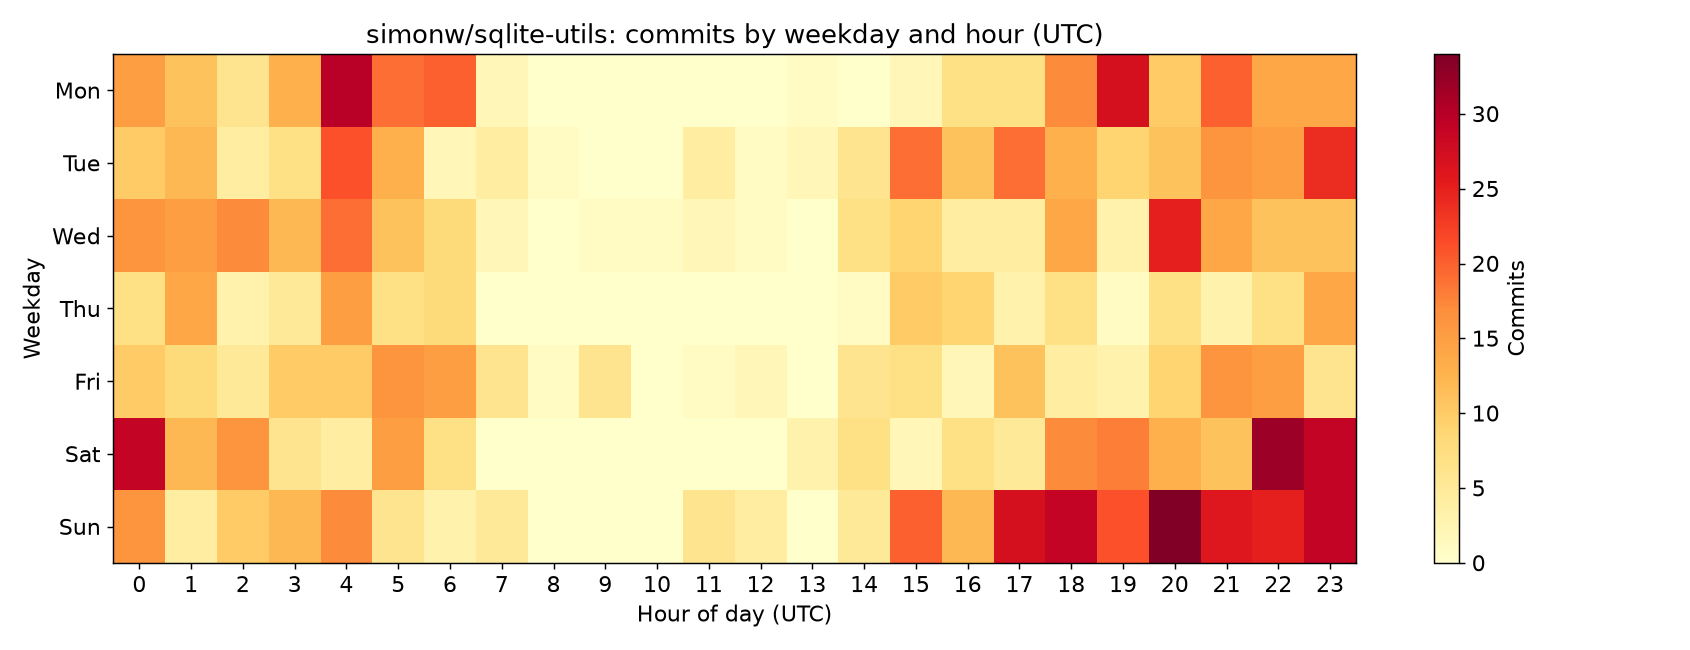

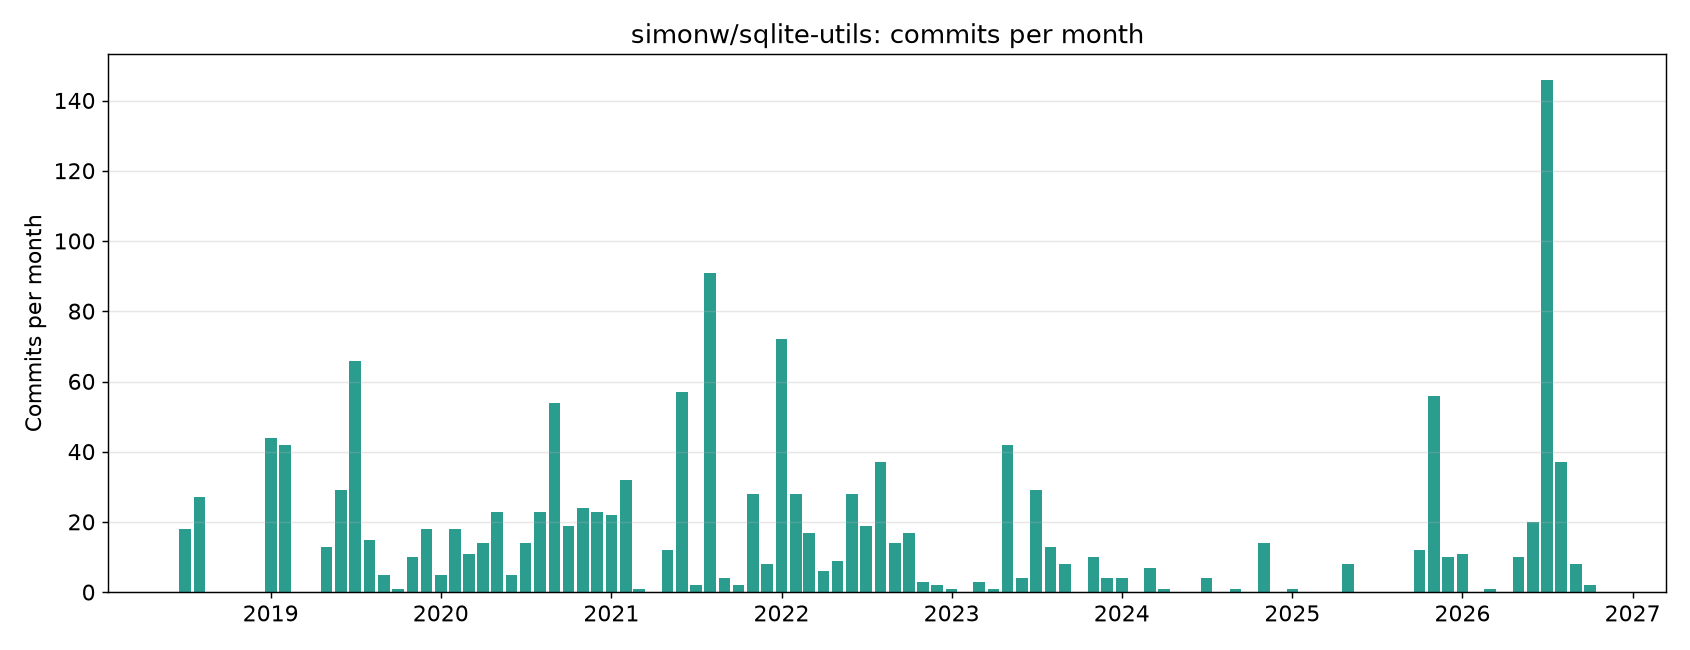

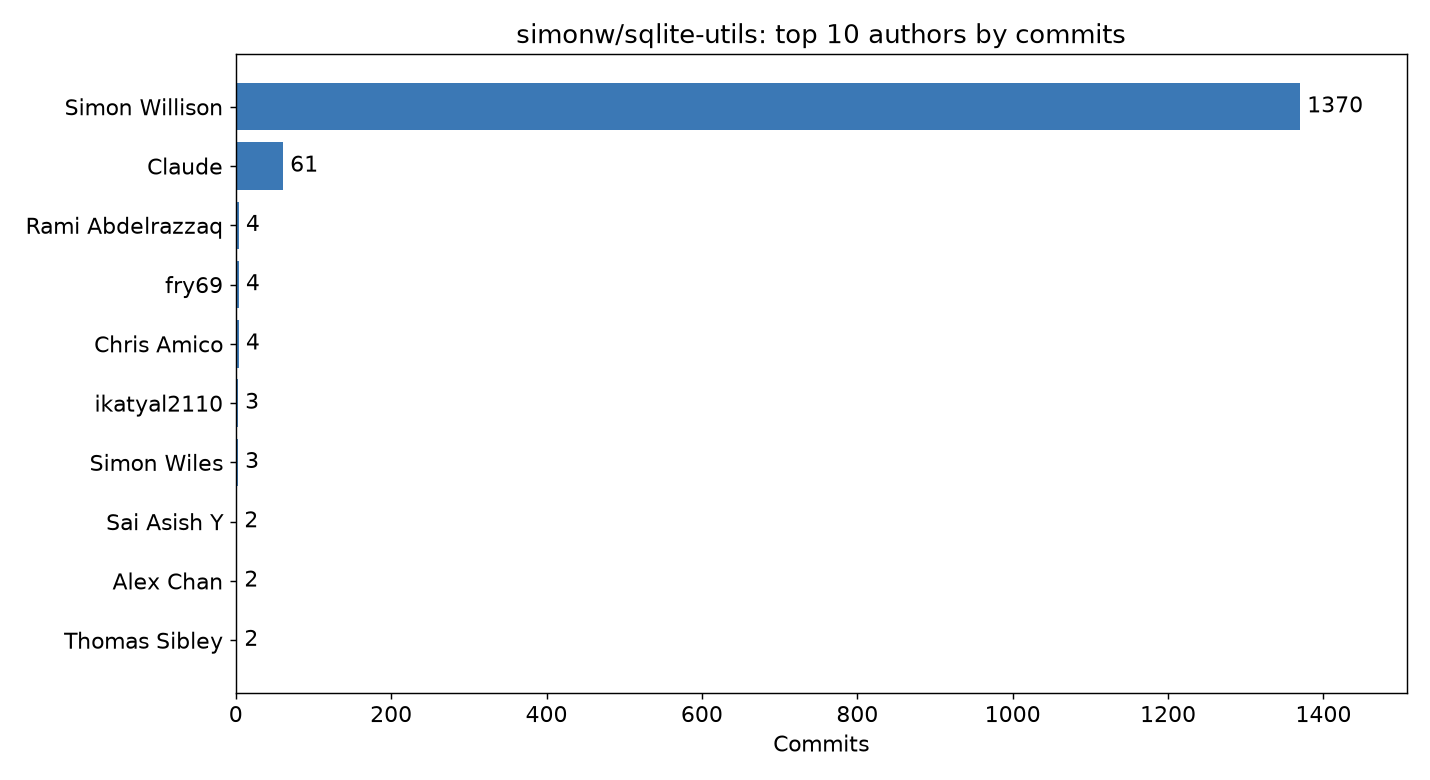

In [8]:
outputs_b = {p.name.split("_", 1)[1]: p.read_bytes() for p in RECORDED.glob("globex_*") if p.suffix in (".png", ".json")}
show_report(outputs_b)

## 6. The event log is the record

Everything the agent did is stored server-side as events, retrievable later with no help from this notebook. For a "Repo health" button that's useful for debugging. For the lab's *security* reviewer, it's the audit trail.

In [9]:
from collections import Counter
if REPLAY:
    events = [json.loads(l) for l in (RECORDED / "acme-corp_events.jsonl").read_text().splitlines()]
    types = Counter(e["type"] for e in events)
else:
    types = Counter(e.type for e in client.beta.sessions.events.list(SESSION_A))
for t, n in types.most_common():
    print(f"{n:4}  {t}")

   2  span.model_request_start
   2  span.model_request_end
   1  session.status_running
   1  session.thread_status_running
   1  user.message
   1  agent.tool_use
   1  agent.tool_result
   1  agent.thinking
   1  agent.message
   1  session.thread_status_idle
   1  session.usage
   1  session.status_idle


## What you just saw → what you'll build

| You wrote… | You did **not** write… |
|---|---|
| One environment config, one agent config | An agent loop, tool executors, retries |
| `sessions.create` per request | Containers, a job queue, cleanup |
| An event printer | A conversation store or transcript DB |
| A file download | A way to get artifacts out of a VM |

**In the lab** the stakes go up. The repository is **untrusted**: a vendor package that might be phoning home. You'll give the agent a **custom tool** that runs in *your* process to record its security verdict. Then you'll **crash your own app** in the middle of a review and reattach to a session that never stopped.

In [10]:
# Cleanup (optional): sessions keep their sandbox state for a while; delete them when done.
# for sid in (SESSION_A,):
#     client.beta.sessions.delete(sid)